# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** John Praveen  &nbsp;&nbsp; **Index No:** `220491B`  
**GitHub:** https://github.com/john-praveen/EN4554-Assignment-2

**Contents:** Setup · Task 1 Backpropagation · Task 2 Optimizers · Task 3 Regularization & residual connections · Task 4 Best CNN (optional)

## 0. Setup

This section covers the environment, the fixed seeds, and the CIFAR-10 data pipeline. CIFAR-10 is split 45k train / 5k validation, and each channel is normalised with the **training-split** mean and std. The test set is not touched until Task 4.

In [ ]:
import random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [ ]:
from datasets import load_dataset

train_data = load_dataset('uoft-cs/cifar10', split='train')
X = torch.tensor(np.stack([np.array(im) for im in train_data['img']])).permute(0, 3, 1, 2).float() / 255
y = torch.tensor(train_data['label'])

perm = torch.randperm(50000)
X_tr, y_tr = X[perm[:45000]], y[perm[:45000]]
X_va, y_va = X[perm[45000:]], y[perm[45000:]]

mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)
std  = X_tr.std(dim=(0, 2, 3), keepdim=True)
X_tr = ((X_tr - mean) / std).to(device); y_tr = y_tr.to(device)
X_va = ((X_va - mean) / std).to(device); y_va = y_va.to(device)
print(X_tr.shape, X_va.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])


In [4]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

**Notes.** The data is kept on the GPU as plain tensors, so no `DataLoader` is needed. The mean and std come from the 45k training images only, so nothing leaks from validation or test. The test set is left untouched until Task 4.

## Task 1: Backpropagation

### 1(a) Layers with explicit forward and backward

Each layer stores what it needs in `forward` and uses it in `backward`, which receives `dout`, the gradient of the loss with respect to the layer's output, and returns the gradient with respect to its input. The gradients are derived by hand, with no autograd.

| Layer | Forward | Backward |
|---|---|---|
| Linear | `out = x @ W + b` | `dW = xᵀ @ dout`, `db = sum(dout)`, `dx = dout @ Wᵀ` |
| ReLU | `out = max(0, x)` | `dx = dout * (x > 0)` |
| Sigmoid (used in 1d) | `out = 1 / (1 + e^-x)` | `dx = dout * out * (1 - out)` |
| Softmax + cross-entropy | `L = -mean(log softmax(z)[y])` | `dz = (softmax(z) - onehot(y)) / N` |

The softmax and the cross-entropy are combined into one layer because their combined gradient simplifies to `(p - onehot) / N`. Linear weights use He initialisation, `N(0, 2/n_in)`.

In [5]:
class Linear:
    def __init__(self, n_in, n_out):
        self.W = torch.randn(n_in, n_out, device=device) * (2 / n_in) ** 0.5
        self.b = torch.zeros(n_out, device=device)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.out = 1 / (1 + torch.exp(-x))
        return self.out
    def backward(self, dout):
        return dout * self.out * (1 - self.out)

class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values
        logp = z - z.logsumexp(1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y), device=y.device), y].mean()
    def backward(self):
        d = self.p.clone()
        d[torch.arange(len(self.y), device=self.y.device), self.y] -= 1
        return d / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1]))
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCE()
        self.linears = [l for l in self.layers if isinstance(l, Linear)]
    def logits(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def forward(self, x, y):
        return self.loss_fn.forward(self.logits(x), y)
    def backward(self):
        d = self.loss_fn.backward()
        for l in reversed(self.layers): d = l.backward(d)

### 1(b) Gradient check

A small MLP (3072-32-16-10) is checked in float64 on 16 validation images. The manual gradients are compared with:
1. **autograd**, on every entry, using `torch.allclose`;
2. **centred finite differences**, `(L(w+ε) − L(w−ε)) / 2ε` with `ε = 1e-5`, on 50 randomly chosen entries of each parameter tensor. Checking every entry would take too long.

The relative error is `‖a − b‖ / (‖a‖ + ‖b‖)`.

In [6]:
set_seed()
xs, ys = X_va[:16].reshape(16, -1).cpu().double(), y_va[:16].cpu()
net = MLP([3072, 32, 16, 10])
for l in net.linears:
    l.W, l.b = l.W.cpu().double(), l.b.cpu().double()

net.forward(xs, ys); net.backward()
manual  = [g for l in net.linears for g in (l.dW, l.db)]
tensors = [t for l in net.linears for t in (l.W, l.b)]
names   = [f'{n}{i + 1}' for i in range(len(net.linears)) for n in ('W', 'b')]

params = [t.clone().requires_grad_() for t in tensors]
h = xs
for i in range(0, len(params), 2):
    h = h @ params[i] + params[i + 1]
    if i < len(params) - 2: h = F.relu(h)
F.cross_entropy(h, ys).backward()

def fd_grad(t, idx, eps=1e-5):
    flat, g = t.view(-1), []
    for i in idx:
        old = flat[i].item()
        flat[i] = old + eps; lp = net.forward(xs, ys).item()
        flat[i] = old - eps; lm = net.forward(xs, ys).item()
        flat[i] = old
        g.append((lp - lm) / (2 * eps))
    return torch.tensor(g, dtype=torch.float64)

rel = lambda a, b: ((a - b).norm() / (a.norm() + b.norm())).item()
print(f"{'param':6s} {'rel.err vs autograd':>20s} {'allclose':>9s} {'rel.err vs finite-diff':>23s} {'allclose':>9s}")
for name, gm, p, t in zip(names, manual, params, tensors):
    idx  = torch.randperm(t.numel())[:50]
    g_fd = fd_grad(t, idx)
    g_m  = gm.reshape(-1)[idx]
    print(f'{name:6s} {rel(gm, p.grad):20.2e} {str(torch.allclose(gm, p.grad, rtol=1e-6, atol=1e-9)):>9s} '
          f'{rel(g_m, g_fd):23.2e} {str(torch.allclose(g_m, g_fd, rtol=1e-4, atol=1e-7)):>9s}')

param   rel.err vs autograd  allclose  rel.err vs finite-diff  allclose
W1                 9.85e-17      True                1.64e-10      True
b1                 8.10e-17      True                1.92e-10      True
W2                 7.38e-17      True                7.50e-11      True
b2                 9.05e-17      True                6.07e-11      True
W3                 5.22e-17      True                9.42e-11      True
b3                 5.56e-17      True                9.16e-11      True


### 1(c) Training the MLP with SGD

A 3072-256-128-10 MLP is trained on flattened, normalised images with plain mini-batch SGD (learning rate 0.05, batch size 128, 15 epochs). The update is applied by hand, `W -= lr * dW`.

epoch  1  train loss 1.730  val acc 0.4138
epoch  2  train loss 1.464  val acc 0.4770
epoch  3  train loss 1.351  val acc 0.4848
epoch  4  train loss 1.263  val acc 0.4930
epoch  5  train loss 1.192  val acc 0.5008
epoch  6  train loss 1.130  val acc 0.4864
epoch  7  train loss 1.073  val acc 0.4940
epoch  8  train loss 1.021  val acc 0.5164
epoch  9  train loss 0.968  val acc 0.5064
epoch 10  train loss 0.918  val acc 0.5106
epoch 11  train loss 0.870  val acc 0.4964
epoch 12  train loss 0.827  val acc 0.5164
epoch 13  train loss 0.789  val acc 0.4824
epoch 14  train loss 0.748  val acc 0.4894
epoch 15  train loss 0.712  val acc 0.4908


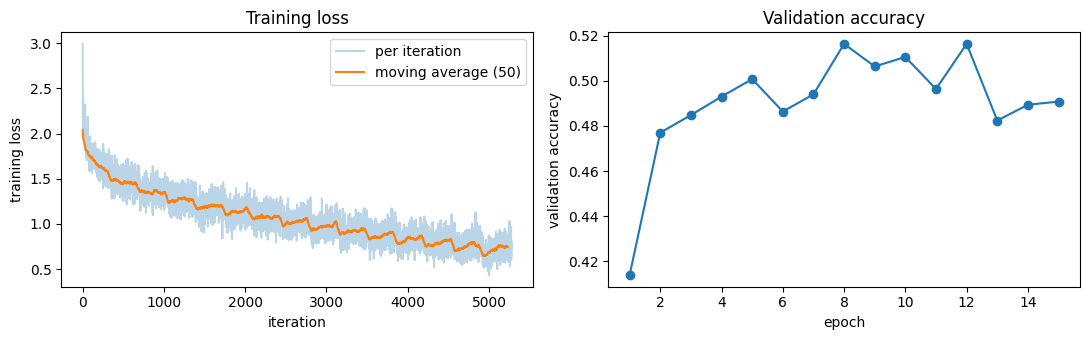

Final validation accuracy: 0.4908


In [7]:
set_seed()
Xf_tr, Xf_va = X_tr.reshape(len(X_tr), -1), X_va.reshape(len(X_va), -1)
net = MLP([3072, 256, 128, 10])
lr, bs, epochs = 0.05, 128, 15
losses, val_accs = [], []

for ep in range(epochs):
    perm = torch.randperm(len(Xf_tr), device=device)
    n_iters = 0
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        losses.append(net.forward(Xf_tr[idx], y_tr[idx]).item())
        net.backward()
        for l in net.linears:
            l.W -= lr * l.dW
            l.b -= lr * l.db
        n_iters += 1
    val_accs.append((net.logits(Xf_va).argmax(1) == y_va).float().mean().item())
    print(f'epoch {ep + 1:2d}  train loss {np.mean(losses[-n_iters:]):.3f}  val acc {val_accs[-1]:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses, alpha=.3, label='per iteration')
ax[0].plot(np.convolve(losses, np.ones(50) / 50, mode='valid'), label='moving average (50)')
ax[0].set(xlabel='iteration', ylabel='training loss', title='Training loss'); ax[0].legend()
ax[1].plot(range(1, epochs + 1), val_accs, marker='o')
ax[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')
plt.tight_layout(); plt.show()
print(f'Final validation accuracy: {val_accs[-1]:.4f}')

### 1(d) Per-layer gradient norms in a 10-layer MLP at initialisation

A 10-layer MLP (3072 → 256 × 9 → 10, so 10 `Linear` layers) is built with sigmoid and with ReLU. The seed and the He initialisation are the same for both. The only difference is the activation. One backward pass is run on a batch of 256 training images, and the Frobenius norm of `dW` is recorded for each layer.

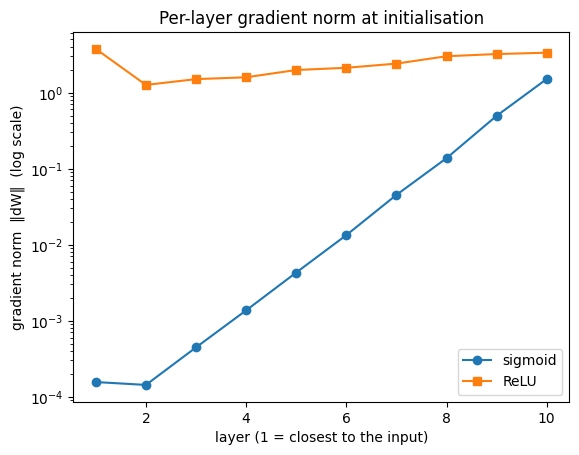

layer  1   sigmoid 1.56e-04   ReLU 3.76e+00
layer  2   sigmoid 1.43e-04   ReLU 1.26e+00
layer  3   sigmoid 4.45e-04   ReLU 1.51e+00
layer  4   sigmoid 1.37e-03   ReLU 1.59e+00
layer  5   sigmoid 4.30e-03   ReLU 1.99e+00
layer  6   sigmoid 1.33e-02   ReLU 2.12e+00
layer  7   sigmoid 4.51e-02   ReLU 2.41e+00
layer  8   sigmoid 1.37e-01   ReLU 3.01e+00
layer  9   sigmoid 4.95e-01   ReLU 3.22e+00
layer 10   sigmoid 1.51e+00   ReLU 3.35e+00


In [8]:
def layer_grad_norms(act):
    set_seed()
    net = MLP([3072] + [256] * 9 + [10], act)
    net.forward(Xf_tr[:256], y_tr[:256]); net.backward()
    return [l.dW.norm().item() for l in net.linears]

g_sig, g_relu = layer_grad_norms(Sigmoid), layer_grad_norms(ReLU)
plt.semilogy(range(1, 11), g_sig,  marker='o', label='sigmoid')
plt.semilogy(range(1, 11), g_relu, marker='s', label='ReLU')
plt.xlabel('layer (1 = closest to the input)'); plt.ylabel('gradient norm  ‖dW‖  (log scale)')
plt.title('Per-layer gradient norm at initialisation'); plt.legend(); plt.show()
for i, (a, b) in enumerate(zip(g_sig, g_relu), 1): print(f'layer {i:2d}   sigmoid {a:.2e}   ReLU {b:.2e}')